In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [2]:
data = {
    "Study_Hours": [1, 2, 4, 5, 1, 2, 4, 5],
    "Attendance": [50, 60, 65, 70, 80, 85, 90, 95],
    "Result": [
        "Fail", "Fail", "Fail", "Fail",
        "Pass", "Pass", "Pass", "Pass"
    ]
}

df = pd.DataFrame(data)

In [3]:
print("Student Dataset:")
print(df)

Student Dataset:
   Study_Hours  Attendance Result
0            1          50   Fail
1            2          60   Fail
2            4          65   Fail
3            5          70   Fail
4            1          80   Pass
5            2          85   Pass
6            4          90   Pass
7            5          95   Pass


In [4]:
X = df[["Study_Hours", "Attendance"]]
y = df["Result"]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("\nTraining Records:")
print(len(X_train))

print("\nTesting Records:")
print(len(X_test))


Training Records:
6

Testing Records:
2


In [7]:
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=2,
    random_state=42
)

In [8]:
model.fit(X_train, y_train)

print("\nDecision Tree Model Trained Successfully!")


Decision Tree Model Trained Successfully!


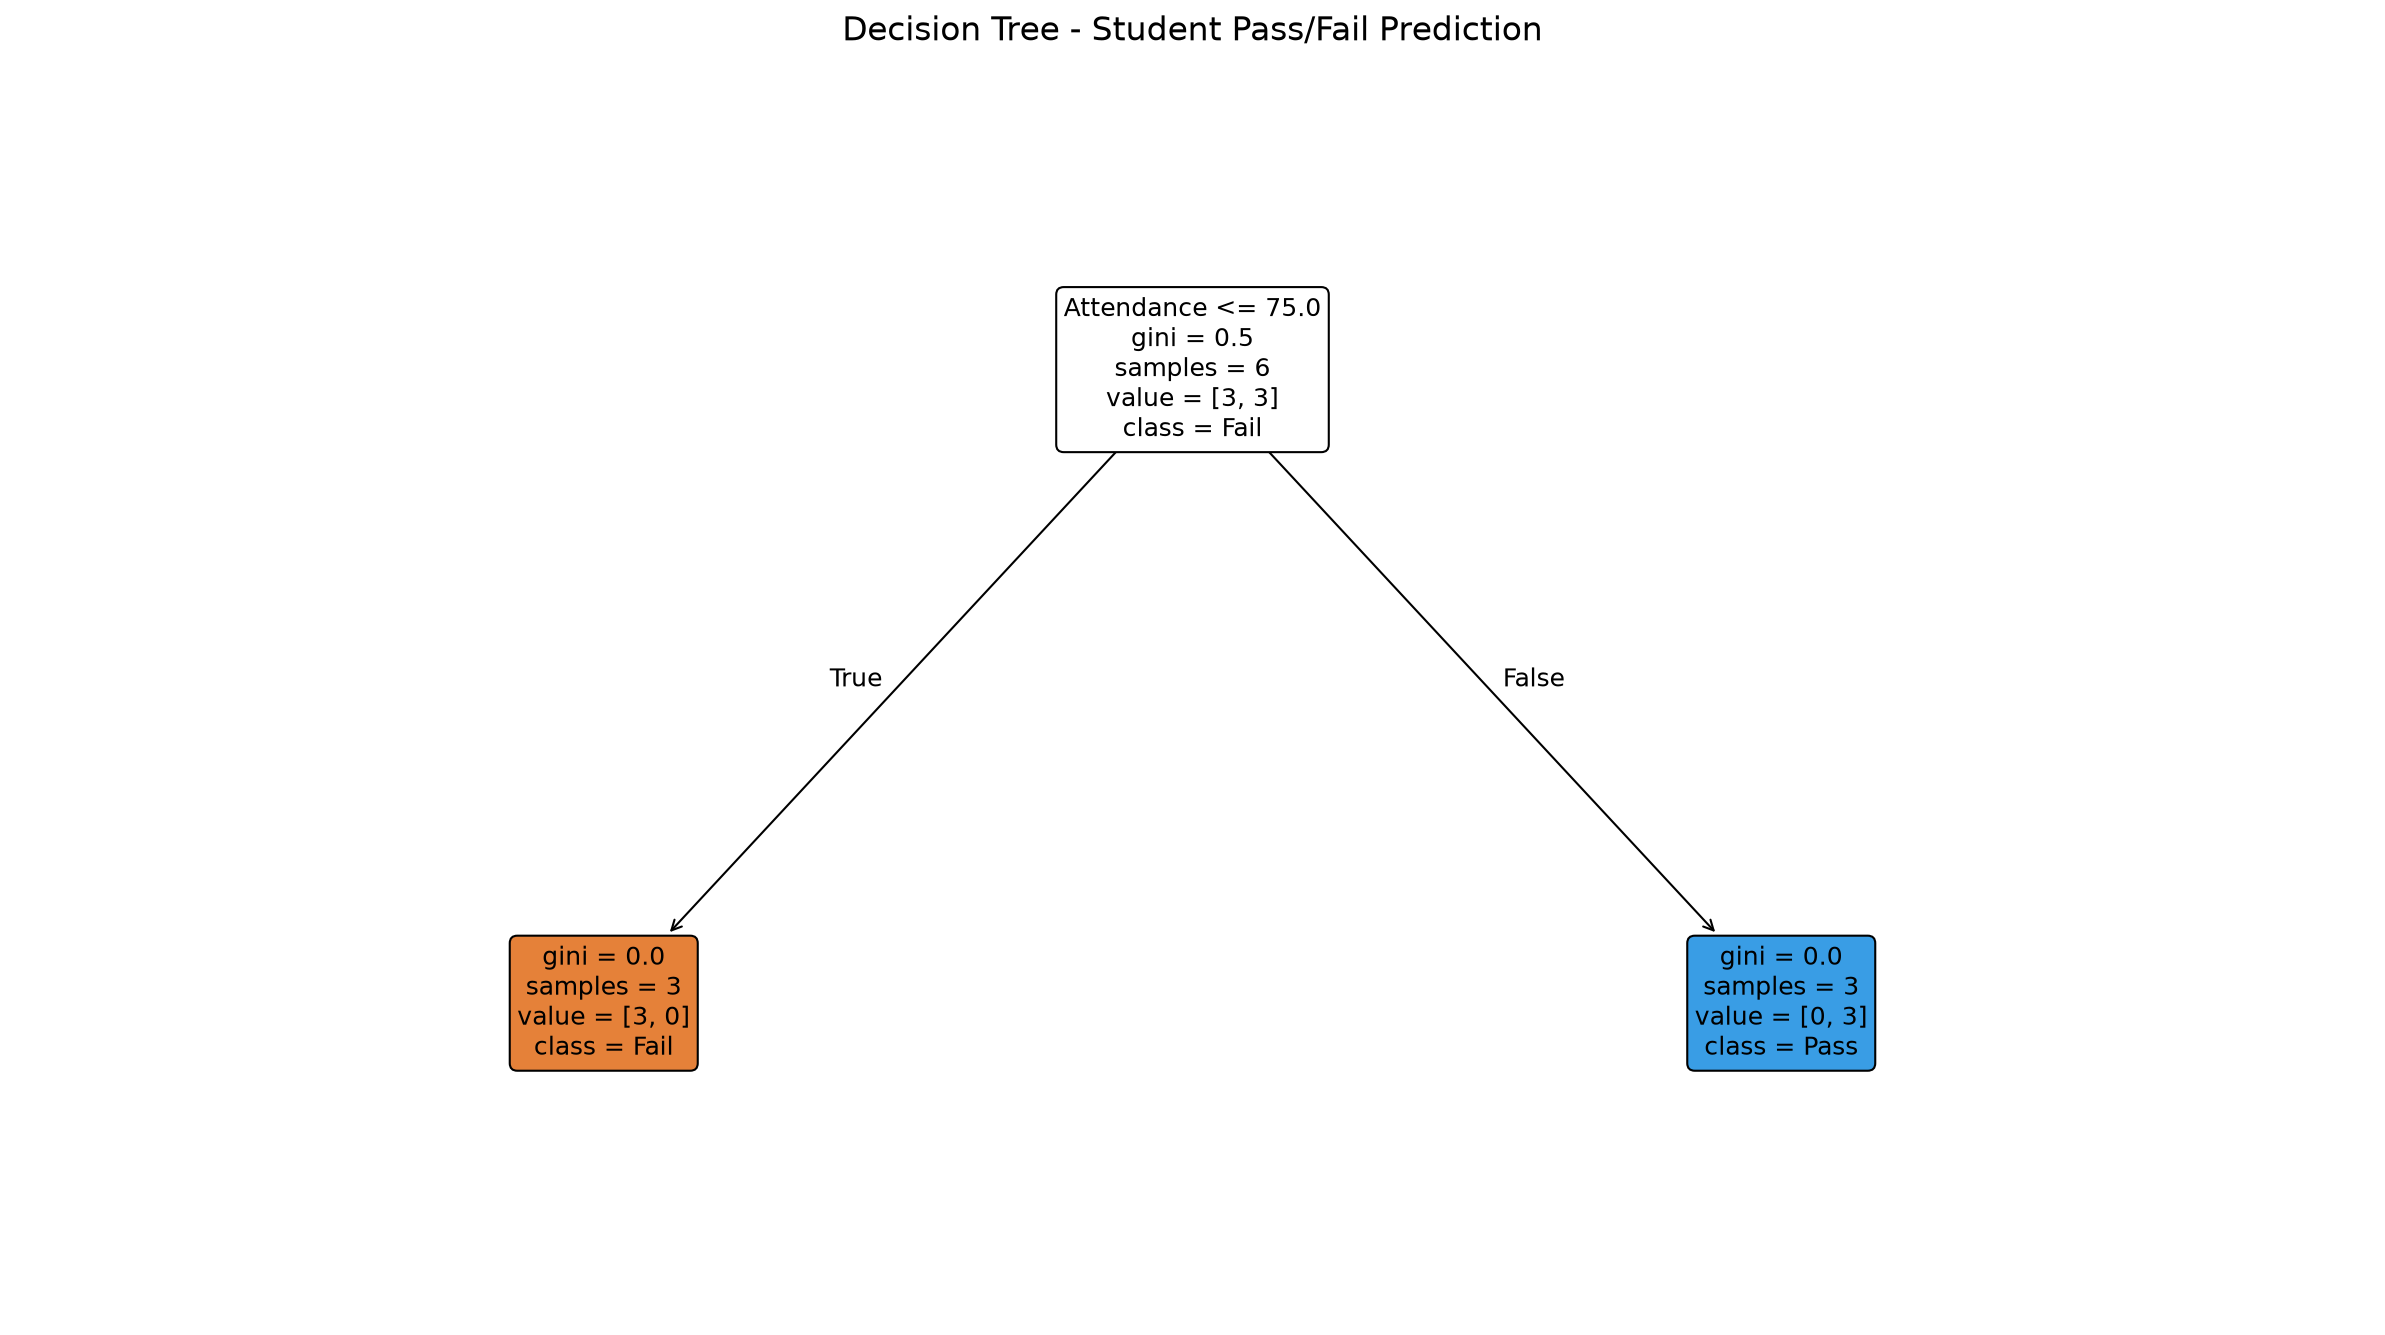

In [9]:
plt.figure(figsize=(16, 9), dpi=150)

plot_tree(
    model,
    feature_names=["Study_Hours", "Attendance"],
    class_names=["Fail", "Pass"],
    filled=True,
    rounded=True,
    proportion=False,
    precision=2,
    fontsize=12
)

plt.title("Decision Tree - Student Pass/Fail Prediction", fontsize=16)
plt.tight_layout()
plt.show()

In [10]:
y_pred = model.predict(X_test)

print("\nActual Results:")
print(y_test.values)

print("\nPredicted Results:")
print(y_pred)


Actual Results:
<StringArray>
['Fail', 'Pass']
Length: 2, dtype: str

Predicted Results:
['Fail' 'Pass']


In [11]:
accuracy = accuracy_score(y_test, y_pred)
print("\nModel Accuracy:", accuracy * 100, "%")


Model Accuracy: 100.0 %



Confusion Matrix:
[[1 0]
 [0 1]]


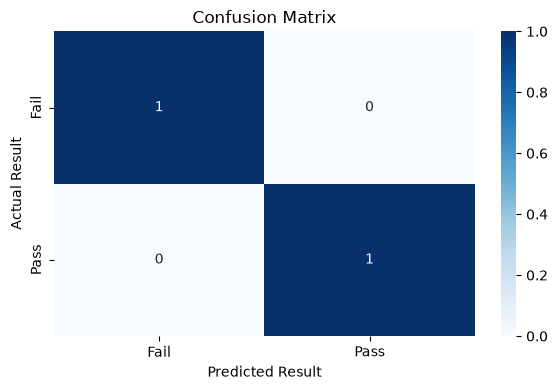

In [12]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Fail", "Pass"]
)

print("\nConfusion Matrix:")
print(cm)

# Visualize Confusion Matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [14]:
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=["Fail", "Pass"],
        zero_division=0
    )
)


Classification Report:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         1
        Pass       1.00      1.00      1.00         1

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2

